In [195]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.naive_bayes import GaussianNB as GNB
from sklearn.model_selection import train_test_split as tts
from astroML.utils import completeness_contamination as cc
from sklearn.metrics import roc_curve
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.metrics import confusion_matrix
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

In [151]:
df = pd.read_csv('galaxyquasar.csv')
df.head()

,u,g,r,i,z,class,z1,zerr
0,18.97213,18.53676,18.58280,18.34936,18.29215,QSO,0.522819,0.000155
1,19.24592,17.47646,16.47817,16.04472,15.68851,GALAXY,0.122846,0.000028
2,19.43536,17.70268,16.91565,16.58327,16.39128,GALAXY,0.000000,0.000000
3,19.31626,18.18312,17.39591,16.94549,16.65395,GALAXY,0.147435,0.000009
4,19.28828,19.11188,18.88937,18.80013,18.49183,QSO,2.011455,0.000631


In [152]:
df = np.array(df)
u = df.T[0]
g = df.T[1]
r = df.T[2]
i = df.T[3]
z = df.T[4]
target = df.T[5]
redshift = df.T[6]
rs_err = df.T[7]

u_g = u-g
g_r = g-r
r_i = r-i
i_z = i-z

In [153]:
for i in range(len(target)):
    if target[i] == 'QSO': target[i] = int(0)
    elif target[i] == 'GALAXY': target[i] = int(1)
    else: print(target[i], ': class not recognized (index:', i, ')')
print(target)

[0 1 1 ... 1 1 1]


In [154]:
X = np.array([u_g, g_r, r_i, i_z, redshift]).T
X.shape

(50000, 5)

In [155]:
X_train, X_test, y_train, y_true = tts(X, target, train_size=0.7, random_state=22)
print(X_train.shape, X_test.shape, y_train.shape, y_true.shape)
y_train = y_train.astype('int')
y_true = y_true.astype('int')

(35000, 5) (15000, 5) (35000,) (15000,)


# GNB with subsamples

Let's first try to find the most important feature(s)

In [156]:
rfr = RFR()
rfr.fit(X_train, y_train)
importances = rfr.feature_importances_
forder = np.argsort(importances)[::-1] #features order
print(forder)

[4 0 1 2 3]


* $z$ seems the most important features, as colors follow up in $\lambda$-increasing order

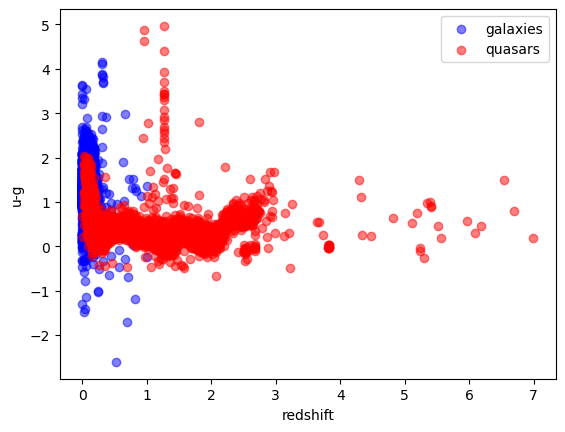

In [157]:
gals = np.where(target==1)
qso = np.where(target==0)

plt.scatter(redshift[gals], u_g[gals], c='blue', ls='None', alpha=0.5, label='galaxies')
plt.scatter(redshift[qso], u_g[qso], c='red', ls='None', alpha=0.5, label='quasars')
plt.xlabel('redshift')
plt.ylabel('u-g')
plt.legend()
plt.show()

## Only $z$

In [158]:
subX_1 = X.T[4]
print(subX_1.shape)

X1_train, X1_test, y1_train, y1_true = tts(subX_1, target, train_size=0.7, random_state=22)
y1_train = y1_train.astype('int')
y1_true = y1_true.astype('int')

(50000,)


In [159]:
gnb = GNB()
gnb.fit(X1_train[:,np.newaxis], y1_train[:,np.newaxis])

y1_pred = gnb.predict(X1_test[:,np.newaxis])

score = gnb.score(X1_test[:,np.newaxis], y1_true[:,np.newaxis])
score

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


0.9845333333333334

## Only $z$ and $u-g$

In [160]:
subX_2 = np.array([X.T[4], X.T[0]]).T
print(subX_2.shape)

X2_train, X2_test, y2_train, y2_true = tts(subX_2, target, train_size=0.7, random_state=22)
y2_train = y2_train.astype('int')
y2_true = y2_true.astype('int')

(50000, 2)


In [161]:
gnb = GNB()
gnb.fit(X2_train, y2_train)

y2_pred = gnb.predict(X2_test)

score = gnb.score(X2_test, y2_true)
score

0.9877333333333334

# GNB

In [188]:
gnb = GNB()
gnb.fit(X_train, y_train)

y_pred = gnb.predict(X_test)

score_gnb = gnb.score(X_test, y_true)
score_gnb

0.9824

In [186]:
y_prob = gnb.predict_proba(X_test)[:,1]
fpr_gnb, tpr_gnb, thresholds_gnb = roc_curve(y_true, y_prob)

comp_gnb = fpr_gnb
a_gnb = np.mean(y_true==1)
cont_gnb = ((1-a_gnb)*fpr_gnb) / (a_gnb*tpr_gnb+(1-a_gnb)*fpr_gnb)
eff_gnb = 1-cont_gnb

/var/folders/qk/_k66m61n20l_yhkclqkkp8780000gn/T/ipykernel_90751/2146617105.py:6: RuntimeWarning: invalid value encountered in divide
  cont_gnb = ((1-a_gnb)*fpr_gnb) / (a_gnb*tpr_gnb+(1-a_gnb)*fpr_gnb)


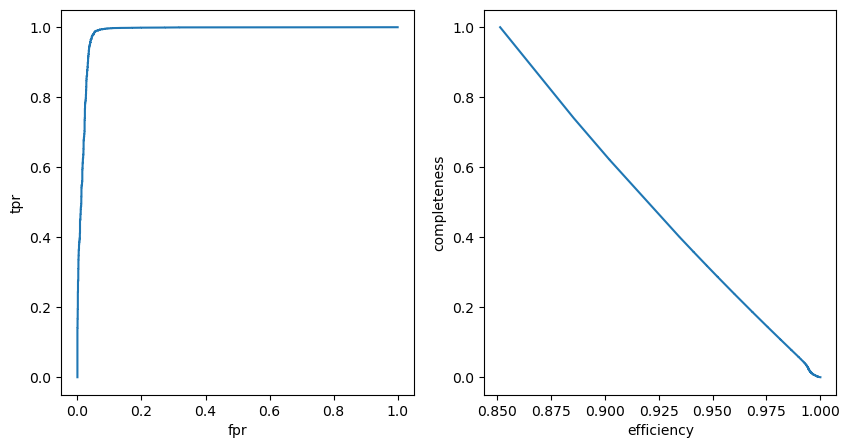

In [187]:
fig, axes = plt.subplots(ncols=2, figsize=(10,5))
axes[0].plot(fpr_gnb, tpr_gnb)
axes[0].set_xlabel('fpr')
axes[0].set_ylabel('tpr')
axes[1].plot(eff_gnb, comp_gnb)
axes[1].set_xlabel('efficiency')
axes[1].set_ylabel('completeness')
plt.show()

# Quadratic and Linear Discriminant Analysis

In [198]:
qda = QDA()
qda.fit(X_train, y_train)
y_pred_qda = qda.predict(X_test)

lda = LDA()
lda.fit(X_train, y_train)
y_pred_lda = lda.predict(X_test)

In [199]:
score_lda = lda.score(X_test, y_true)
print(score_lda)
score_qda = qda.score(X_test, y_true)
print(score_qda)

0.9743333333333334
0.9871333333333333


In [200]:
y_prob_lda = lda.predict_proba(X_test)[:,1]
fpr_lda, tpr_lda, thresholds_lda = roc_curve(y_true, y_prob_lda)

y_prob_qda = qda.predict_proba(X_test)[:,1]
fpr_qda, tpr_qda, thresholds_qda = roc_curve(y_true, y_prob_qda)

comp_lda = fpr_lda
a_lda = np.mean(y_true==1)
cont_lda = ((1-a_lda)*fpr_lda) / (a_lda*tpr_lda+(1-a_lda)*fpr_lda)
eff_lda = 1-cont_lda

comp_qda = fpr_qda
a_qda = np.mean(y_true==1)
cont_qda = ((1-a_qda)*fpr_qda) / (a_qda*tpr_qda+(1-a_qda)*fpr_qda)
eff_qda = 1-cont_qda

/var/folders/qk/_k66m61n20l_yhkclqkkp8780000gn/T/ipykernel_90751/29538149.py:9: RuntimeWarning: invalid value encountered in divide
  cont_lda = ((1-a_lda)*fpr_lda) / (a_lda*tpr_lda+(1-a_lda)*fpr_lda)
/var/folders/qk/_k66m61n20l_yhkclqkkp8780000gn/T/ipykernel_90751/29538149.py:14: RuntimeWarning: invalid value encountered in divide
  cont_qda = ((1-a_qda)*fpr_qda) / (a_qda*tpr_qda+(1-a_qda)*fpr_qda)


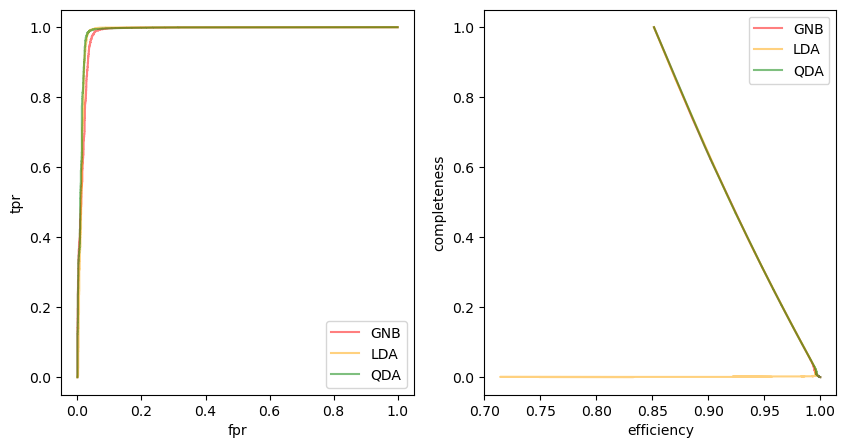

In [208]:
fig, axes = plt.subplots(ncols=2, figsize=(10,5))
axes[0].plot(fpr_gnb, tpr_gnb, c='red', alpha=0.5, label='GNB')
axes[1].plot(eff_gnb, comp_gnb, c='red', alpha=0.5, label='GNB')
axes[0].plot(fpr_lda, tpr_lda, c='orange', alpha=0.5, label='LDA')
axes[1].plot(eff_lda, comp_lda, c='orange', alpha=0.5, label='LDA')
axes[0].plot(fpr_qda, tpr_qda, c='green', alpha=0.5, label='QDA')
axes[1].plot(eff_qda, comp_qda, c='green', alpha=0.5, label='QDA')
axes[0].set_xlabel('fpr')
axes[0].set_ylabel('tpr')
axes[1].set_xlabel('efficiency')
axes[1].set_ylabel('completeness')
axes[0].legend()
axes[1].legend()
plt.show()